**Comparison of the Qiskit, PennyLane and Cirq Quantum Software Development Kits**


In [46]:
!pip install -q qiskit pennylane cirq matplotlib seaborn pandas


In [6]:
import time
import inspect
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import qiskit
import pennylane as qml
import cirq

from qiskit.quantum_info import Statevector

print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("Qiskit:", qiskit.__version__)
print("PennyLane:", qml.__version__)
print("Cirq:", cirq.__version__)

print("CPU:", platform.processor())

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Qiskit: 2.6.2
PennyLane: 0.45.1
Cirq: 1.7.0
CPU: x86_64


In [7]:
import numpy as np
import pennylane as qml
import cirq

from qiskit import QuantumCircuit


# =========================
# 1. BELL STATE
# =========================

def qiskit_bell():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    return qc


def pennylane_bell():
    dev = qml.device("default.qubit", wires=2)

    @qml.qnode(dev)
    def circuit():
        qml.Hadamard(0)
        qml.CNOT([0, 1])
        return qml.state()

    return circuit


def cirq_bell():
    q = cirq.LineQubit.range(2)

    return cirq.Circuit(
        cirq.H(q[0]),
        cirq.CNOT(q[0], q[1])
    )


# =========================
# 2. GROVER'S SEARCH
# =========================

def qiskit_grover():
    qc = QuantumCircuit(3)

    for i in range(3):
        qc.h(i)

    for _ in range(2):
        # Oracle for |101>
        qc.x(1)
        qc.h(2)
        qc.mcx([0, 1], 2)
        qc.h(2)
        qc.x(1)

        # Diffusion
        for i in range(3):
            qc.h(i)
            qc.x(i)

        qc.h(2)
        qc.mcx([0, 1], 2)
        qc.h(2)

        for i in range(3):
            qc.x(i)
            qc.h(i)

    return qc


def pennylane_grover():
    dev = qml.device("default.qubit", wires=3)

    @qml.qnode(dev)
    def circuit():

        for i in range(3):
            qml.Hadamard(i)

        for _ in range(2):
            # Oracle
            qml.PauliX(1)
            qml.Hadamard(2)
            qml.Toffoli([0, 1, 2])
            qml.Hadamard(2)
            qml.PauliX(1)

            # Diffusion
            for i in range(3):
                qml.Hadamard(i)
                qml.PauliX(i)

            qml.Hadamard(2)
            qml.Toffoli([0, 1, 2])
            qml.Hadamard(2)

            for i in range(3):
                qml.PauliX(i)
                qml.Hadamard(i)

        return qml.state()

    return circuit


def cirq_grover():
    q = cirq.LineQubit.range(3)
    circuit = cirq.Circuit()

    circuit.append(cirq.H.on_each(*q))

    for _ in range(2):
        # Oracle
        circuit.append(cirq.X(q[1]))
        circuit.append(cirq.H(q[2]))
        circuit.append(cirq.X(q[2]).controlled_by(q[0], q[1]))
        circuit.append(cirq.H(q[2]))
        circuit.append(cirq.X(q[1]))

        # Diffusion
        circuit.append(cirq.H.on_each(*q))
        circuit.append(cirq.X.on_each(*q))

        circuit.append(cirq.H(q[2]))
        circuit.append(cirq.X(q[2]).controlled_by(q[0], q[1]))
        circuit.append(cirq.H(q[2]))

        circuit.append(cirq.X.on_each(*q))
        circuit.append(cirq.H.on_each(*q))

    return circuit


# =========================
# 3. QUANTUM FOURIER TRANSFORM
# =========================

def qiskit_qft():
    n = 4
    qc = QuantumCircuit(n)

    for j in range(n):
        qc.h(j)

        for k in range(j + 1, n):
            qc.cp(np.pi / (2 ** (k - j)), k, j)

    for i in range(n // 2):
        qc.swap(i, n - i - 1)

    return qc


def pennylane_qft():
    dev = qml.device("default.qubit", wires=4)

    @qml.qnode(dev)
    def circuit():
        qml.QFT(wires=range(4))
        return qml.state()

    return circuit


def cirq_qft():
    q = cirq.LineQubit.range(4)
    return cirq.Circuit(cirq.qft(*q))


# =========================
# 4. VARIATIONAL CIRCUIT
# =========================

def qiskit_variational():
    qc = QuantumCircuit(4)

    angles = [0.2, 0.4, 0.6, 0.8]

    for _ in range(2):
        for i in range(4):
            qc.ry(angles[i], i)
            qc.rz(angles[i], i)

        for i in range(3):
            qc.cx(i, i + 1)

    return qc


def pennylane_variational():
    dev = qml.device("default.qubit", wires=4)

    @qml.qnode(dev)
    def circuit():
        angles = [0.2, 0.4, 0.6, 0.8]

        for _ in range(2):
            for i in range(4):
                qml.RY(angles[i], wires=i)
                qml.RZ(angles[i], wires=i)

            for i in range(3):
                qml.CNOT([i, i + 1])

        return qml.state()

    return circuit


def cirq_variational():
    q = cirq.LineQubit.range(4)
    angles = [0.2, 0.4, 0.6, 0.8]

    circuit = cirq.Circuit()

    for _ in range(2):
        for i in range(4):
            circuit.append(cirq.ry(angles[i])(q[i]))
            circuit.append(cirq.rz(angles[i])(q[i]))

        for i in range(3):
            circuit.append(cirq.CNOT(q[i], q[i + 1]))

    return circuit


print("All 12 quantum circuit functions defined successfully!")

All 12 quantum circuit functions defined successfully!


In [8]:
circuits = {
    "Bell state": {
        "Qiskit": qiskit_bell,
        "PennyLane": pennylane_bell,
        "Cirq": cirq_bell
    },

    "Grover's search": {
        "Qiskit": qiskit_grover,
        "PennyLane": pennylane_grover,
        "Cirq": cirq_grover
    },

    "Quantum Fourier Transform": {
        "Qiskit": qiskit_qft,
        "PennyLane": pennylane_qft,
        "Cirq": cirq_qft
    },

    "Variational circuit": {
        "Qiskit": qiskit_variational,
        "PennyLane": pennylane_variational,
        "Cirq": cirq_variational
    }
}

print("Total circuits:", len(circuits))
print("Total implementations:", sum(len(v) for v in circuits.values()))

for name, frameworks in circuits.items():
    print(name, ":", list(frameworks.keys()))

Total circuits: 4
Total implementations: 12
Bell state : ['Qiskit', 'PennyLane', 'Cirq']
Grover's search : ['Qiskit', 'PennyLane', 'Cirq']
Quantum Fourier Transform : ['Qiskit', 'PennyLane', 'Cirq']
Variational circuit : ['Qiskit', 'PennyLane', 'Cirq']


Benchmark simulation time

This measures how long each framework takes to execute its circuit.
- Warm-up runs: 10
- Measurement repetitions: 100
- Metric: Mean execution time in milliseconds
- Standard deviation: Measures variation between runs

In [17]:
WARMUP = 10
REPEATS = 100

CIRQ_SIMULATOR = cirq.Simulator()


def execute(framework, circuit):

    if framework == "Qiskit":
        return Statevector.from_instruction(circuit)

    elif framework == "PennyLane":
        return circuit()

    elif framework == "Cirq":
        return CIRQ_SIMULATOR.simulate(circuit)


timing_results = []

for circuit_name, frameworks in circuits.items():

    for framework, circuit_function in frameworks.items():

        circuit = circuit_function()

        # Warm-up
        for _ in range(WARMUP):
            execute(framework, circuit)

        execution_times = []

        # Actual benchmarking
        for _ in range(REPEATS):

            start = time.perf_counter()

            execute(framework, circuit)

            end = time.perf_counter()

            execution_times.append((end - start) * 1000)

        timing_results.append({
            "Circuit": circuit_name,
            "Framework": framework,
            "Mean Time (ms)": np.mean(execution_times),
            "Std Dev (ms)": np.std(execution_times)
        })


df_time = pd.DataFrame(timing_results)

display(df_time)

,Circuit,Framework,Mean Time (ms),Std Dev (ms)
0,Bell state,Qiskit,0.834020,1.088765
1,Bell state,PennyLane,3.570422,3.578012
2,Bell state,Cirq,0.736945,0.144340
3,Grover's search,Qiskit,1.748815,0.085610
4,Grover's search,PennyLane,4.398296,0.376946
5,Grover's search,Cirq,5.355646,0.902332
6,Quantum Fourier Transform,Qiskit,0.894576,0.088148
7,Quantum Fourier Transform,PennyLane,0.884073,0.096977
8,Quantum Fourier Transform,Cirq,2.139373,0.187327
9,Variational circuit,Qiskit,1.209801,0.231337


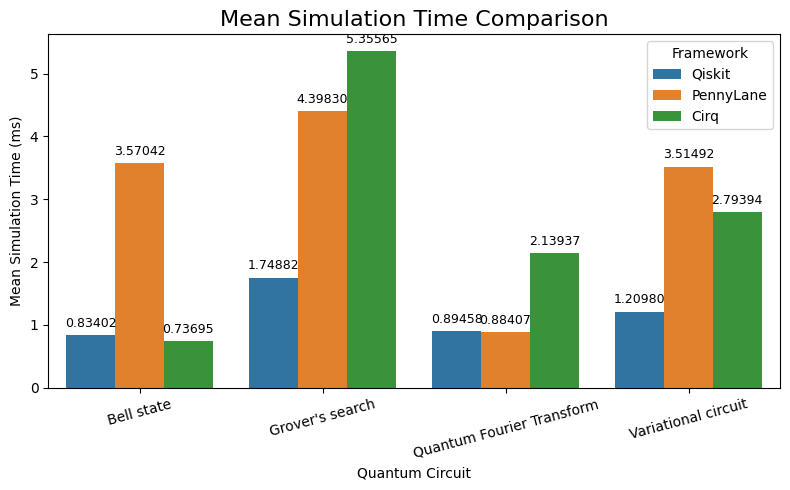

In [43]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df_time,
    x="Circuit",
    y="Mean Time (ms)",
    hue="Framework"
)

plt.title("Mean Simulation Time Comparison", fontsize=16)
plt.xlabel("Quantum Circuit")
plt.ylabel("Mean Simulation Time (ms)")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.5f",
        padding=4,
        fontsize=9
    )

plt.legend(title="Framework")
plt.tight_layout()

plt.savefig(
    "Figure_1_Simulation_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Program effort (Lines of Code)

This counts the non-empty, non-comment lines in each circuit implementation.

In [20]:
#LOC comparison graph


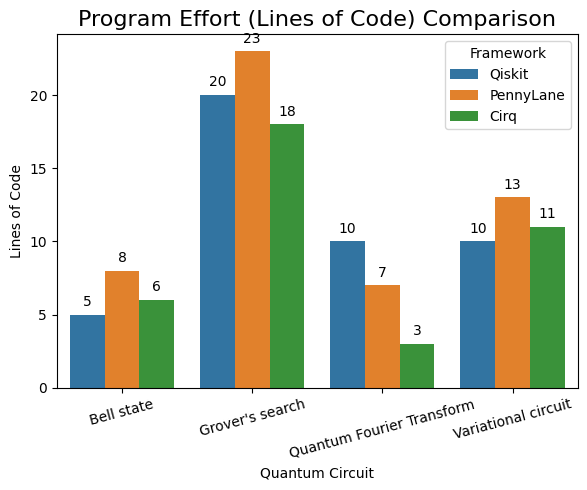

In [45]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    data=df_loc,
    x="Circuit",
    y="Lines of Code",
    hue="Framework"
)

plt.title("Program Effort (Lines of Code) Comparison", fontsize=16)
plt.xlabel("Quantum Circuit")
plt.ylabel("Lines of Code")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.legend(title="Framework")
plt.tight_layout()

plt.savefig(
    "Figure_2_LOC_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Circuit depth and gate count**

Calculate circuit depth and gate count

In [23]:
metric_results = []

for circuit_name, frameworks in circuits.items():

    for framework, circuit_function in frameworks.items():

        circuit = circuit_function()

        if framework == "Qiskit":
            depth = circuit.depth()
            gates = circuit.size()

        elif framework == "PennyLane":
            specs = qml.specs(circuit)()
            resources = specs["resources"]

            depth = resources.depth
            gates = resources.num_gates

        elif framework == "Cirq":
            depth = len(circuit)
            gates = len(list(circuit.all_operations()))

        metric_results.append({
            "Circuit": circuit_name,
            "Framework": framework,
            "Circuit Depth": depth,
            "Gate Count": gates
        })

df_metrics = pd.DataFrame(metric_results)

display(
    df_metrics.style
    .format({
        "Circuit Depth": "{:.0f}",
        "Gate Count": "{:.0f}"
    })
    .set_caption("Circuit Depth and Gate Count Comparison")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#243B53"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        }
    ])
)

,Circuit,Framework,Circuit Depth,Gate Count
0,Bell state,Qiskit,2,2
1,Bell state,PennyLane,2,2
2,Bell state,Cirq,2,2
3,Grover's search,Qiskit,21,43
4,Grover's search,PennyLane,21,43
5,Grover's search,Cirq,21,43
6,Quantum Fourier Transform,Qiskit,8,12
7,Quantum Fourier Transform,PennyLane,1,1
8,Quantum Fourier Transform,Cirq,1,1
9,Variational circuit,Qiskit,9,22


**Gate Details**

In [25]:
gate_details_results = []

for circuit_name, frameworks in circuits.items():

    for framework, circuit_function in frameworks.items():

        circuit = circuit_function()

        if framework == "Qiskit":
            raw_details = circuit.count_ops()

        elif framework == "PennyLane":
            specs = qml.specs(circuit)()
            raw_details = specs["resources"].gate_types

        elif framework == "Cirq":
            raw_details = {}

            for operation in circuit.all_operations():
                gate_name = type(operation.gate).__name__
                raw_details[gate_name] = raw_details.get(gate_name, 0) + 1

        # Remove rotation parameters and keep gate names only
        formatted_details = []

        for gate, count in raw_details.items():

            gate_name = str(gate).split("(")[0].split(".")[-1]

            formatted_details.append(
                f"{gate_name}: {count}"
            )

        gate_details_results.append({
            "Circuit": circuit_name,
            "Framework": framework,
            "Gate Details": ", ".join(formatted_details)
        })


df_gate_details = pd.DataFrame(gate_details_results)

display(
    df_gate_details.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal",
        "max-width": "450px",
        "padding": "10px"
    })
    .set_caption("Gate-wise Distribution Across Quantum Frameworks")
)

,Circuit,Framework,Gate Details
0,Bell state,Qiskit,"h: 1, cx: 1"
1,Bell state,PennyLane,"Hadamard: 1, CNOT: 1"
2,Bell state,Cirq,"HPowGate: 1, CXPowGate: 1"
3,Grover's search,Qiskit,"h: 23, x: 16, ccx: 4"
4,Grover's search,PennyLane,"Hadamard: 23, PauliX: 16, Toffoli: 4"
5,Grover's search,Cirq,"HPowGate: 23, _PauliX: 16, CCXPowGate: 4"
6,Quantum Fourier Transform,Qiskit,"cp: 6, h: 4, swap: 2"
7,Quantum Fourier Transform,PennyLane,QFT: 1
8,Quantum Fourier Transform,Cirq,QuantumFourierTransformGate: 1
9,Variational circuit,Qiskit,"ry: 8, rz: 8, cx: 6"


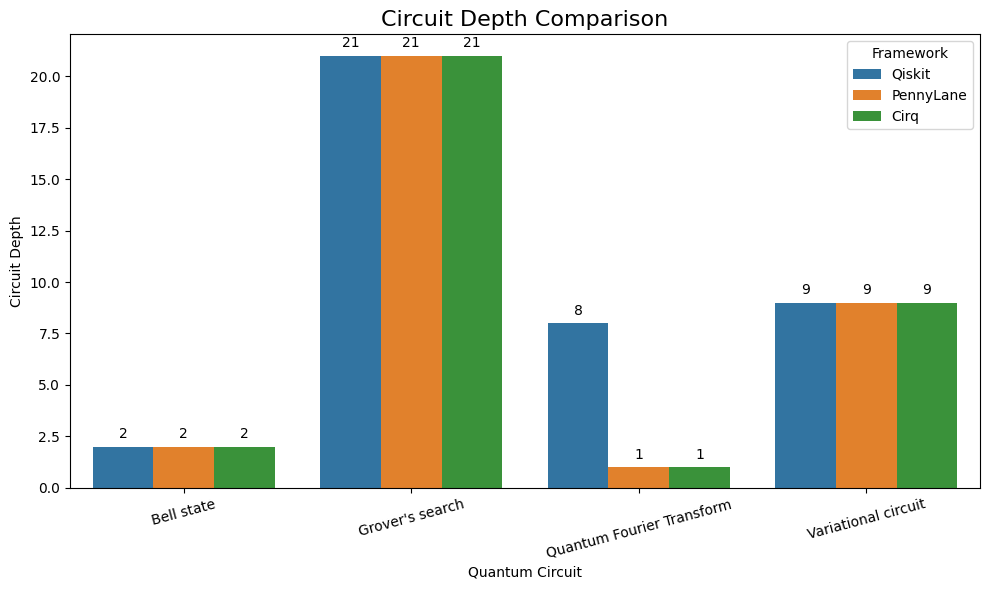

In [35]:
#Circuit depth comparison graph
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_metrics,
    x="Circuit",
    y="Circuit Depth",
    hue="Framework"
)

plt.title("Circuit Depth Comparison", fontsize=16)
plt.xlabel("Quantum Circuit")
plt.ylabel("Circuit Depth")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.legend(title="Framework")
plt.tight_layout()

plt.savefig(
    "Figure_3_Circuit_Depth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

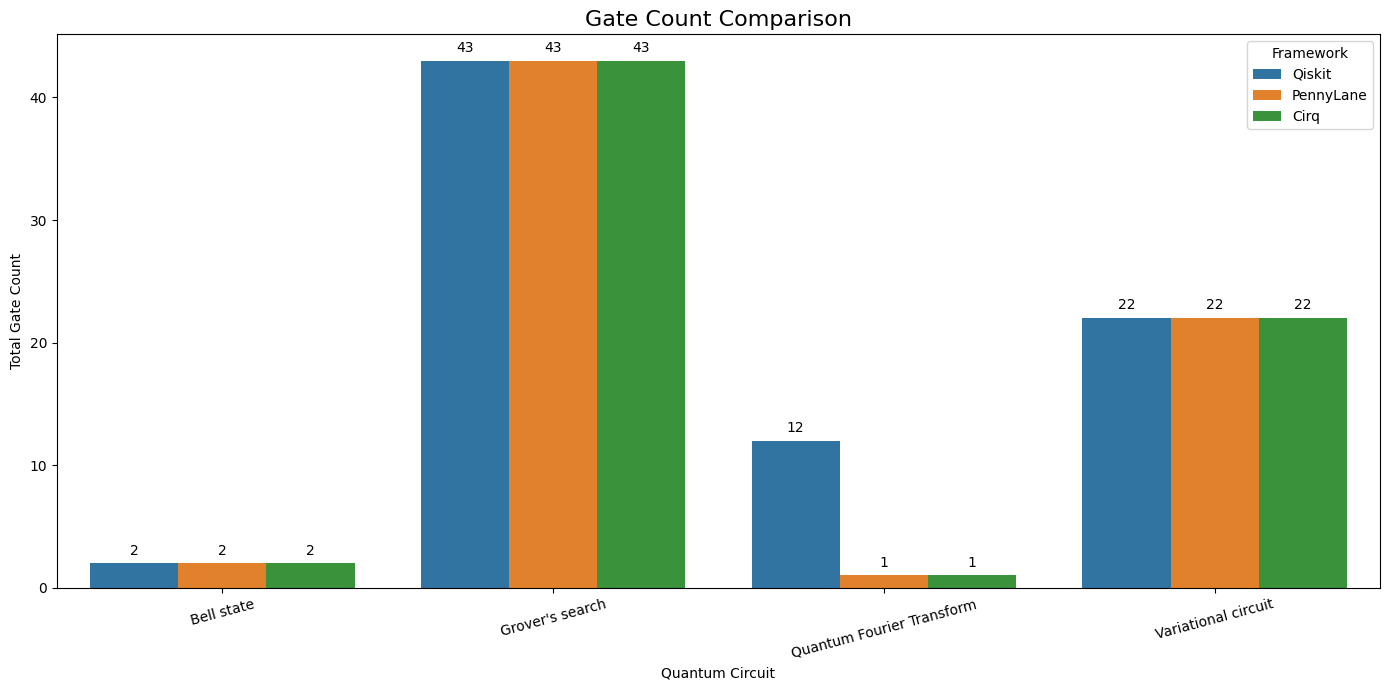

In [37]:
#Gate count comparison graph
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=df_metrics,
    x="Circuit",
    y="Gate Count",
    hue="Framework"
)

plt.title("Gate Count Comparison", fontsize=16)
plt.xlabel("Quantum Circuit")
plt.ylabel("Total Gate Count")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.legend(title="Framework")
plt.tight_layout()

plt.savefig(
    "Figure_4_Gate_Count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()